# 🌸 Clustering com K-Means: uma aula guiada com o Iris

**Machine Learning não supervisionado | Google Colab | Scikit-learn**  
**Público:** estudantes iniciantes em Ciência de Dados e Inteligência Artificial  
**Tempo sugerido:** 3–4 horas (ou duas aulas)  

> **Como utilizar:** execute as células na ordem. Leia as explicações antes de executar cada bloco. Os gráficos são produzidos pelo próprio código, portanto não é necessário enviar arquivos ou baixar o Iris.

### Objetivos de aprendizagem
Ao final, você deverá conseguir: explicar o que é clustering; descrever as etapas do K-Means; justificar o uso de padronização; treinar e visualizar um modelo; selecionar e avaliar diferentes valores de K; e discutir por que grupos matemáticos não equivalem automaticamente a espécies biológicas.

**Roteiro:** 1. Fundamentos → 2. Algoritmo → 3. Iris → 4. Escalonamento → 5. Primeiro K-Means → 6. PCA e visualizações → 7. Escolha de K → 8. Avaliação → 9. Experimentos e exercício final.

## 0. Preparação do ambiente

O Google Colab já inclui normalmente as bibliotecas necessárias. Não é preciso instalar pacotes para executar esta aula. Usaremos `numpy` para operações numéricas, `pandas` para tabelas, `matplotlib` e `seaborn` para gráficos, e `scikit-learn` para os algoritmos.

In [1]:
# Importamos as bibliotecas utilizadas ao longo do notebook.
import numpy as np                       # Vetores e operações matemáticas
import pandas as pd                      # Tabelas e análise de dados
import matplotlib.pyplot as plt          # Construção de gráficos
import seaborn as sns                    # Visualizações estatísticas
import sklearn                           # Biblioteca de Machine Learning

from sklearn.datasets import load_iris   # Dataset Iris incluído no sklearn
from sklearn.cluster import KMeans       # Algoritmo K-Means
from sklearn.preprocessing import StandardScaler  # Padronização
from sklearn.decomposition import PCA    # Redução de dimensionalidade
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             confusion_matrix, davies_bouldin_score)

sns.set_theme(style="whitegrid", context="notebook")
SEMENTE = 42                            # Reprodutibilidade dos experimentos
print("Scikit-learn:", sklearn.__version__)
print("Ambiente pronto para a aula!")

Scikit-learn: 1.9.1
Ambiente pronto para a aula!


# 1. Fundamentos: o que é clustering?

**Aprendizado supervisionado** utiliza exemplos acompanhados de respostas (rótulos) para aprender uma relação entre entradas e saídas. Na classificação, por exemplo, cada flor poderia ter uma espécie informada durante o treinamento.

**Aprendizado não supervisionado** busca estruturas nos dados sem usar respostas conhecidas. **Clustering** é uma família de técnicas que procura agrupar observações semelhantes, segundo alguma medida matemática.

**Atenção:** um cluster é um grupo definido por um procedimento e por uma representação dos dados. Não é necessariamente uma categoria natural ou uma classe biológica. O resultado depende dos atributos, das escalas, da distância e do algoritmo.

### Intuição visual
Imagine pontos em um plano: se houver regiões densas separadas, um algoritmo pode tentar reuni-los em grupos. A figura a seguir é uma ilustração **sintética**, não representa o Iris.

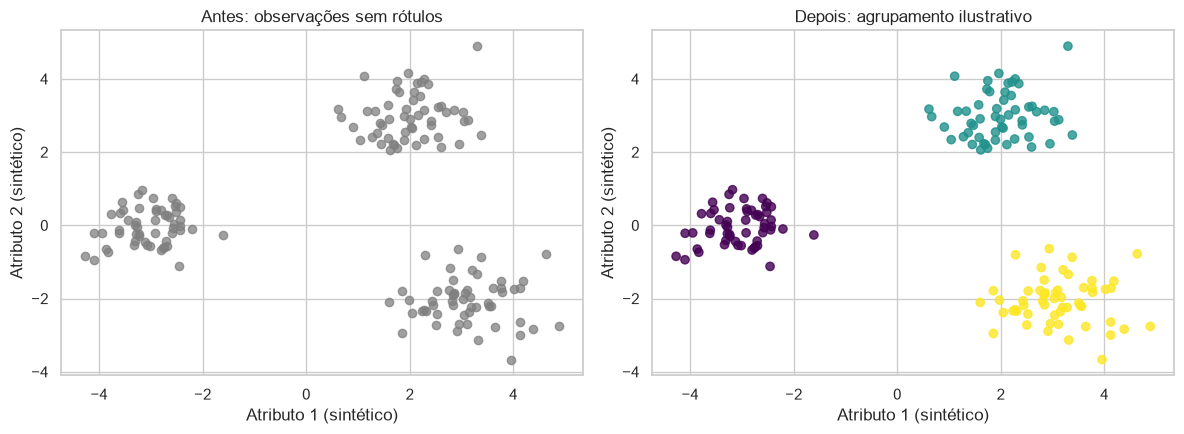

In [2]:
# Criamos três nuvens artificiais apenas para ilustrar a ideia de grupos.
rng = np.random.default_rng(SEMENTE)
centros_demo = np.array([[-3, 0], [2, 3], [3, -2]])
pontos_demo = np.vstack([rng.normal(loc=c, scale=0.65, size=(55, 2))
                         for c in centros_demo])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(pontos_demo[:, 0], pontos_demo[:, 1], color="gray", alpha=0.75)
ax[0].set_title("Antes: observações sem rótulos")
cores_demo = np.repeat(np.arange(3), 55)
ax[1].scatter(pontos_demo[:, 0], pontos_demo[:, 1], c=cores_demo, cmap="viridis", alpha=0.8)
ax[1].set_title("Depois: agrupamento ilustrativo")
for a in ax:
    a.set_xlabel("Atributo 1 (sintético)")
    a.set_ylabel("Atributo 2 (sintético)")
plt.tight_layout()
plt.show()

### Distância euclidiana

Para dois pontos $x=(x_1,\ldots,x_p)$ e $y=(y_1,\ldots,y_p)$, a distância euclidiana é:

$$d(x,y)=\sqrt{\sum_{j=1}^{p}(x_j-y_j)^2}$$

Quanto menor a distância, mais próximos são os pontos **nessa representação**. A distância não define, por si só, similaridade biológica.

**Pergunta de reflexão:** o que acontece quando um atributo varia entre 0 e 1 e outro entre 0 e 10.000? O segundo tende a dominar a distância se não houver tratamento de escala.

In [3]:
# Calculamos a distância entre dois pontos usando duas estratégias.
a = np.array([1.0, 2.0])
b = np.array([4.0, 6.0])
distancia_manual = np.sqrt(np.sum((a - b) ** 2))
distancia_numpy = np.linalg.norm(a - b)
print(f"Distância manual: {distancia_manual:.1f}")
print(f"Distância NumPy:  {distancia_numpy:.1f}")
# Esperado: 5, porque sqrt(3² + 4²) = 5.

Distância manual: 5.0
Distância NumPy:  5.0


# 2. Como o K-Means funciona?

O **K-Means** divide os dados em um número predefinido de grupos, chamado **K**. Cada grupo é representado por um **centroide**, a média dos pontos associados a ele.

### Ciclo do algoritmo
1. Definir o número de clusters K.
2. Inicializar K centroides (geralmente usando a estratégia `k-means++`).
3. **Atribuição:** associar cada ponto ao centroide mais próximo.
4. **Atualização:** recalcular cada centroide como a média dos pontos atribuídos.
5. Repetir os passos 3 e 4 até convergir ou atingir o limite de iterações.

### Função objetivo (inércia / WCSS)

$$J=\sum_{i=1}^{n}\|x_i-\mu_{c_i}\|^2$$

Aqui, $x_i$ é a observação $i$, $\mu_{c_i}$ é o centroide do grupo ao qual ela pertence e $\|\cdot\|^2$ representa a distância euclidiana ao quadrado. O algoritmo busca reduzir essa soma. **Não há garantia de encontrar o mínimo global.**

### Limitações típicas
O método pressupõe que médias e distâncias euclidianas são apropriadas, é sensível à escala e a valores extremos, e costuma funcionar melhor com grupos compactos, aproximadamente convexos. Também exige escolher K antecipadamente.

## 2.1 Simulação passo a passo: atribuir e atualizar

Vamos executar **manualmente uma iteração** com pontos sintéticos em duas dimensões. Observe os centroides iniciais, as atribuições e as médias atualizadas.

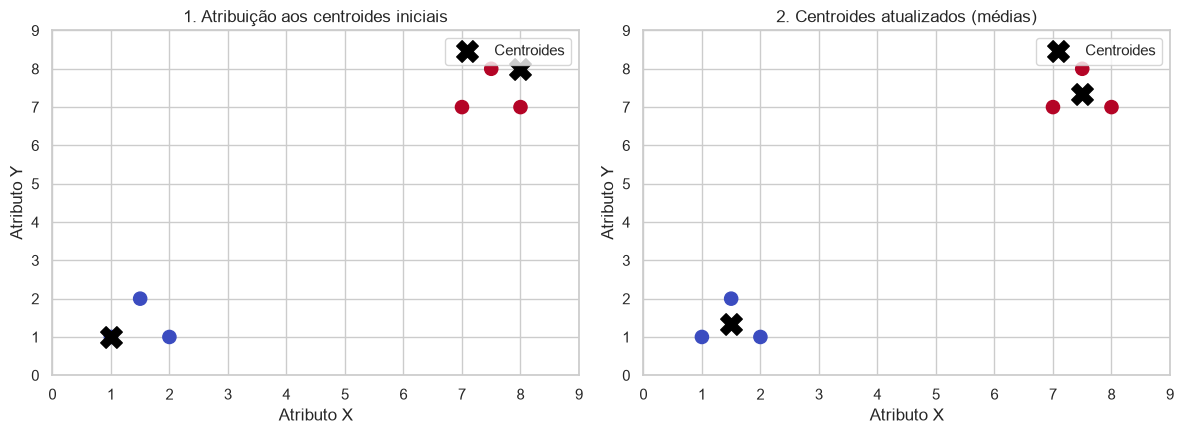

Centroides iniciais:
 [[1. 1.]
 [8. 8.]]
Centroides após atualização:
 [[1.5        1.33333333]
 [7.5        7.33333333]]


In [4]:
# Dados artificiais simples, apenas para explicar a mecânica.
X_passos = np.array([[1, 1], [1.5, 2], [2, 1], [7, 7], [8, 7], [7.5, 8]])
centroides_iniciais = np.array([[1, 1], [8, 8]], dtype=float)

# Para cada ponto, calculamos sua distância a cada centroide.
distancias = np.linalg.norm(X_passos[:, None, :] - centroides_iniciais[None, :, :], axis=2)
# A menor distância determina o grupo provisório.
grupo_passo1 = np.argmin(distancias, axis=1)
# Atualizamos cada centroide pela média dos pontos de seu grupo.
centroides_atualizados = np.vstack([X_passos[grupo_passo1 == k].mean(axis=0)
                                    for k in range(2)])

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, centros, titulo in zip(axs,
    [centroides_iniciais, centroides_atualizados],
    ["1. Atribuição aos centroides iniciais", "2. Centroides atualizados (médias)"]):
    ax.scatter(X_passos[:, 0], X_passos[:, 1], c=grupo_passo1, cmap="coolwarm", s=90)
    ax.scatter(centros[:, 0], centros[:, 1], c="black", marker="X", s=240, label="Centroides")
    ax.set_xlim(0, 9); ax.set_ylim(0, 9)
    ax.set_xlabel("Atributo X"); ax.set_ylabel("Atributo Y")
    ax.set_title(titulo); ax.legend()
plt.tight_layout(); plt.show()
print("Centroides iniciais:\n", centroides_iniciais)
print("Centroides após atualização:\n", centroides_atualizados)

### K-Means++ e `random_state`

A inicialização `k-means++` procura centroides iniciais mais espalhados, reduzindo a chance de soluções ruins. O parâmetro `n_init` executa múltiplas inicializações e retém a solução de menor inércia. `random_state` permite repetir o experimento e obter resultados consistentes no mesmo ambiente.

# 3. Conhecendo o conjunto Iris

O dataset clássico **Iris** contém 150 observações de flores, com quatro medidas em centímetros: comprimento da sépala, largura da sépala, comprimento da pétala e largura da pétala. Há três espécies de referência com 50 observações cada.

**Regra da atividade:** as espécies reais (`target`) **não entram no treinamento**. Elas serão usadas somente na etapa de interpretação externa.

In [5]:
# Carregamos o Iris diretamente do scikit-learn.
iris = load_iris(as_frame=True)
X = iris.data.copy()                     # Somente as quatro medidas
especies = iris.target.copy()            # Rótulos guardados para avaliação externa
nomes_especies = iris.target_names

print("Dimensões de X:", X.shape)
print("Variáveis:", list(X.columns))
print("Espécies de referência:", list(nomes_especies))
display(X.head())

Dimensões de X: (150, 4)
Variáveis: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Espécies de referência: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [6]:
# Verificamos se há valores ausentes e examinamos as estatísticas básicas.
print("Valores ausentes por coluna:")
print(X.isna().sum())
display(X.describe().round(2))
print("Número de espécies (somente para conferência):")
print(especies.value_counts().sort_index())

Valores ausentes por coluna:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


Número de espécies (somente para conferência):
target
0    50
1    50
2    50
Name: count, dtype: int64


## 3.1 Distribuições dos atributos

Histogramas mostram onde se concentram os valores de cada medida. Repare que atributos diferentes podem ter faixas e dispersões diferentes. Isso será importante na padronização.

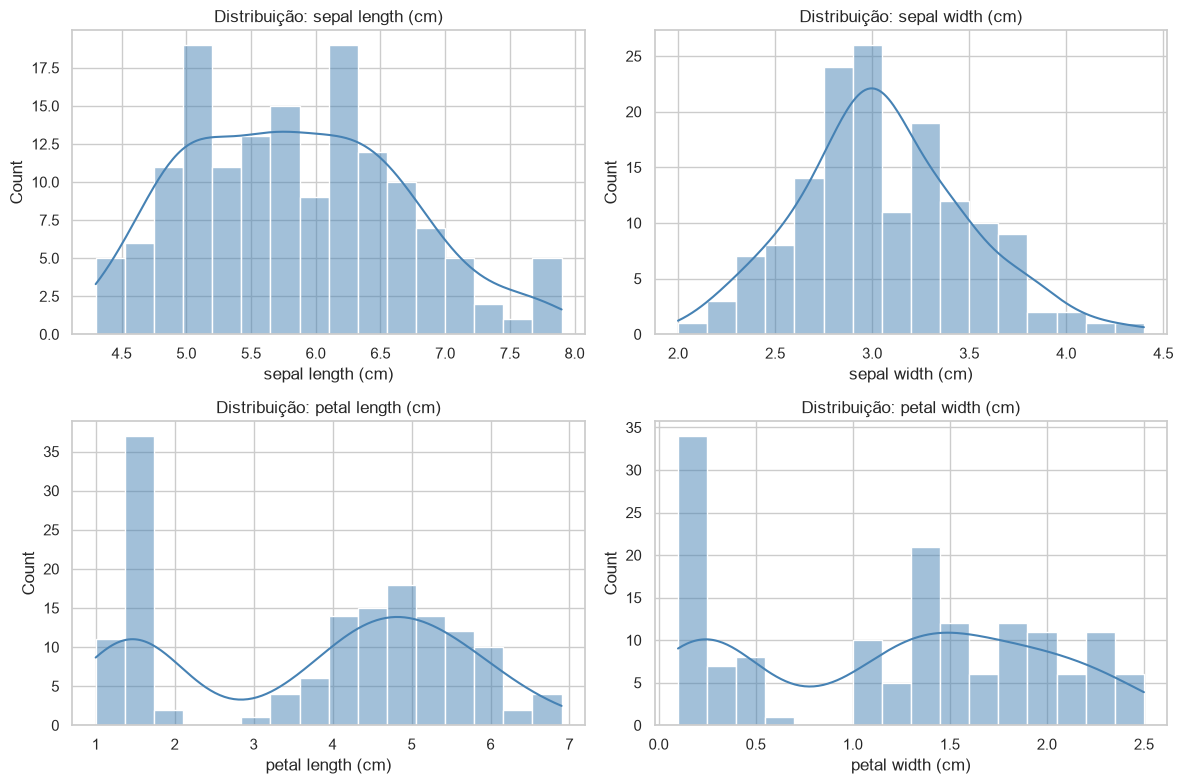

In [7]:
# Quatro histogramas: um para cada atributo do Iris.
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
for eixo, coluna in zip(eixos.ravel(), X.columns):
    sns.histplot(X[coluna], kde=True, bins=16, ax=eixo, color="steelblue")
    eixo.set_title(f"Distribuição: {coluna}")
plt.tight_layout(); plt.show()

## 3.2 Relações entre pares de variáveis

Um gráfico de dispersão permite observar como duas medidas variam juntas. Aqui, as cores representam as espécies **apenas para interpretação exploratória**. O K-Means continuará sem receber essas informações.

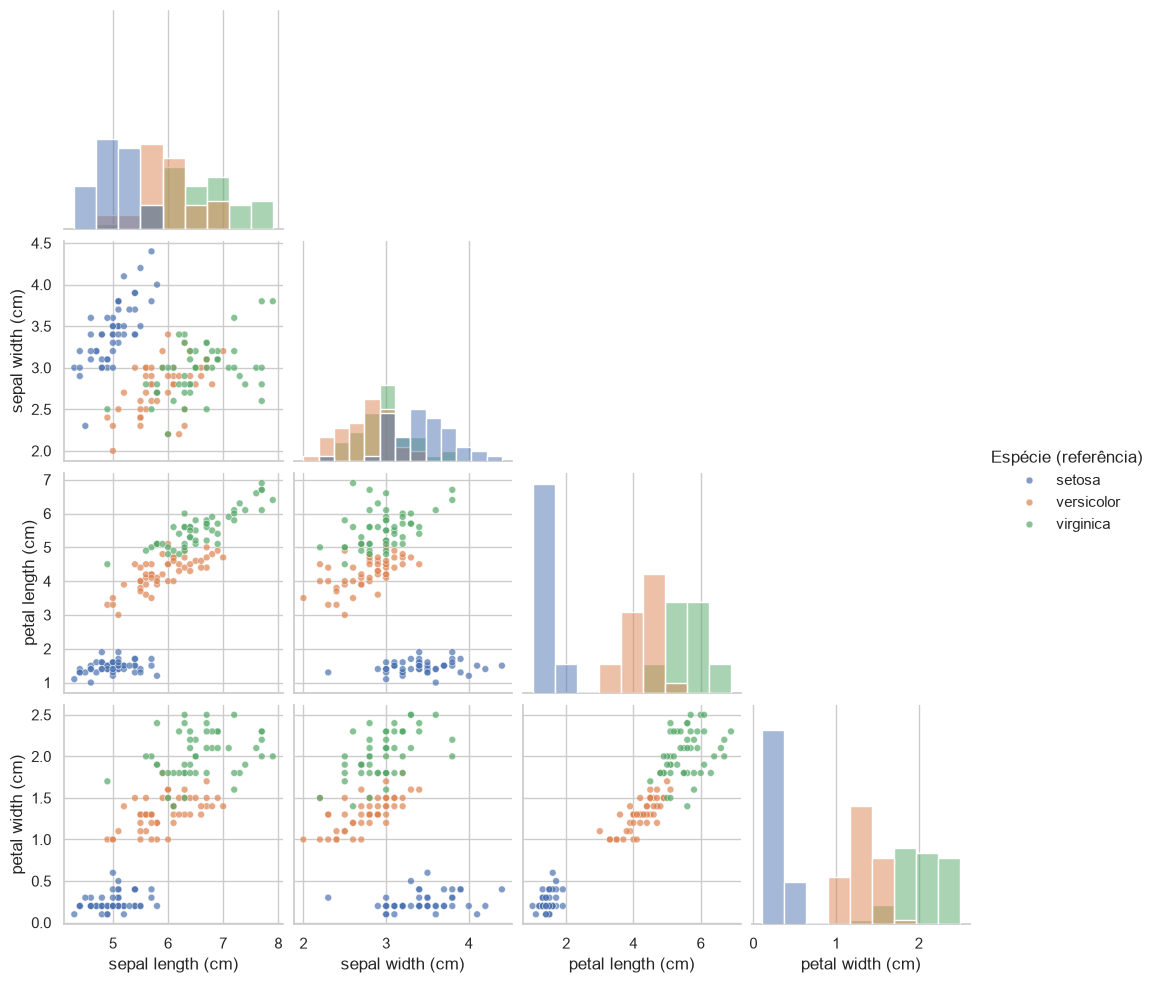

In [8]:
# Criamos uma tabela temporária para a visualização, sem alterar X.
df_visual = X.copy()
df_visual["Espécie (referência)"] = [nomes_especies[i] for i in especies]
sns.pairplot(df_visual, hue="Espécie (referência)", corner=True,
             plot_kws={"alpha": 0.7, "s": 24}, diag_kind="hist")
plt.show()

### Correlação não é equivalência

Se duas variáveis são correlacionadas, elas podem conter informação parcialmente redundante. Isso não implica que uma deva ser removida automaticamente. Vamos observar a matriz de correlação das quatro medidas.

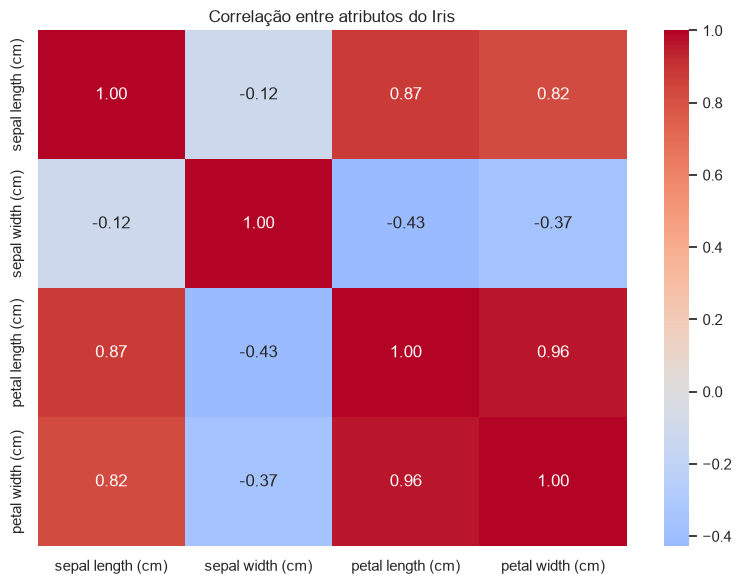

In [9]:
# Correlação de Pearson entre os atributos numéricos.
plt.figure(figsize=(8, 6))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação entre atributos do Iris")
plt.tight_layout(); plt.show()

# 4. Por que padronizar os atributos?

O K-Means utiliza distâncias. Se as variáveis têm escalas diferentes, as de maior variação numérica podem ter mais influência na formação dos clusters.

A padronização por **z-score** transforma cada variável segundo:

$$z=\frac{x-\bar{x}}{s}$$

Em que $\bar{x}$ é a média e $s$ é o desvio-padrão estimado pelo `StandardScaler` (com convenção populacional, `ddof=0`). O resultado tem média aproximadamente zero e desvio-padrão aproximadamente um **nos dados usados para ajustar o scaler**.

**Observação metodológica:** em uma análise não supervisionada exploratória podemos ajustar o scaler ao conjunto completo. Em aplicações preditivas ou validações com dados futuros, ajuste-o somente nos dados de treinamento para evitar vazamento de informação.

In [10]:
# Ajustamos o padronizador apenas às quatro medidas, nunca às espécies.
scaler = StandardScaler()
X_pad = scaler.fit_transform(X)          # Matriz NumPy padronizada
X_pad_df = pd.DataFrame(X_pad, columns=X.columns)

print("Médias após padronização (aproximadamente 0):")
print(X_pad_df.mean().round(4))
print("Desvios-padrão populacionais (aproximadamente 1):")
print(X_pad_df.std(ddof=0).round(4))
display(X_pad_df.head().round(3))

Médias após padronização (aproximadamente 0):
sepal length (cm)   -0.0
sepal width (cm)    -0.0
petal length (cm)   -0.0
petal width (cm)    -0.0
dtype: float64
Desvios-padrão populacionais (aproximadamente 1):
sepal length (cm)    1.0
sepal width (cm)     1.0
petal length (cm)    1.0
petal width (cm)     1.0
dtype: float64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.901,1.019,-1.340,-1.315
1,-1.143,-0.132,-1.340,-1.315
2,-1.385,0.328,-1.397,-1.315
3,-1.507,0.098,-1.283,-1.315
4,-1.022,1.249,-1.340,-1.315


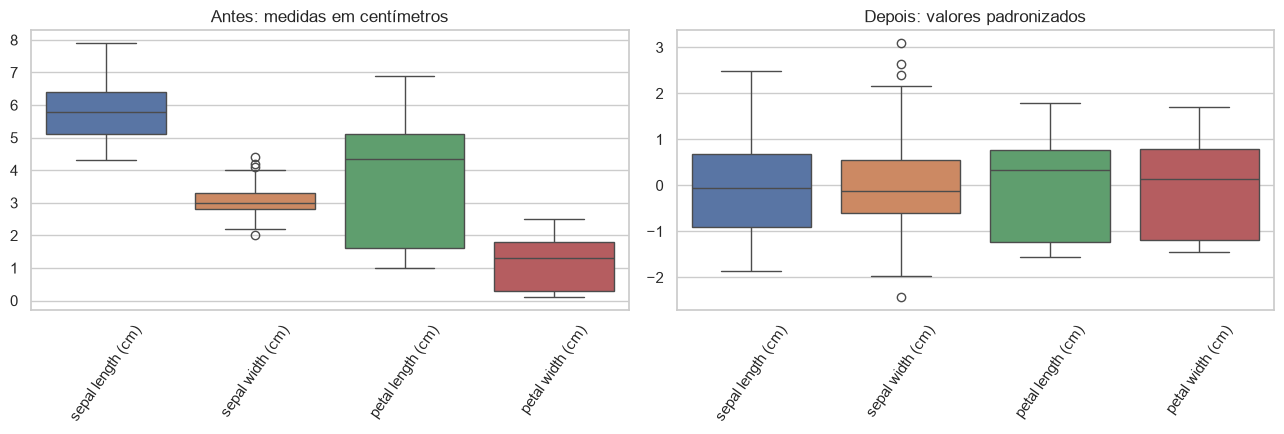

In [11]:
# Comparamos a dispersão antes e depois da padronização.
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=X, ax=axs[0]); axs[0].set_title("Antes: medidas em centímetros")
sns.boxplot(data=X_pad_df, ax=axs[1]); axs[1].set_title("Depois: valores padronizados")
for ax in axs:
    ax.tick_params(axis="x", rotation=55)
plt.tight_layout(); plt.show()

# 5. Treinando o primeiro K-Means

Começaremos com **K = 3** para comparar posteriormente com as três espécies conhecidas do Iris. **Isso é uma escolha didática**, não uma descoberta do algoritmo. Em um problema real, normalmente não sabemos o número apropriado de grupos de antemão.

### Parâmetros
- `n_clusters=3`: quantidade de clusters solicitada;
- `init="k-means++"`: estratégia de inicialização;
- `n_init=20`: número de inicializações independentes;
- `random_state=42`: reprodutibilidade.

In [12]:
# Construímos o modelo. Nenhuma espécie é fornecida ao fit_predict.
modelo = KMeans(n_clusters=3, init="k-means++", n_init=20,
                random_state=SEMENTE)
clusters = modelo.fit_predict(X_pad)

print("Primeiros 20 grupos atribuídos:", clusters[:20])
print("Quantidade de pontos por cluster:")
print(pd.Series(clusters, name="Cluster").value_counts().sort_index())
print(f"Inércia (WCSS): {modelo.inertia_:.3f}")
print(f"Iterações até parar: {modelo.n_iter_}")

Primeiros 20 grupos atribuídos: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Quantidade de pontos por cluster:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64
Inércia (WCSS): 139.820
Iterações até parar: 4


## 5.1 Interpretando os centroides

Os centroides são médias no espaço padronizado. Para interpretá-los em centímetros, aplicamos `inverse_transform`. Atenção: **os números dos clusters são arbitrários**; o cluster 0 não é necessariamente a espécie 0.

In [13]:
# Centroide no espaço padronizado e no espaço original (cm).
centroides_pad = pd.DataFrame(modelo.cluster_centers_, columns=X.columns)
centroides_cm = pd.DataFrame(scaler.inverse_transform(modelo.cluster_centers_),
                            columns=X.columns)
print("Centroides em z-score:")
display(centroides_pad.round(2))
print("Centroides convertidos para centímetros:")
display(centroides_cm.round(2))

Centroides em z-score:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.05,-0.88,0.35,0.28
1,-1.01,0.85,-1.30,-1.25
2,1.14,0.09,1.00,1.02


Centroides convertidos para centímetros:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.80,2.67,4.37,1.41
1,5.01,3.43,1.46,0.25
2,6.78,3.10,5.51,1.97


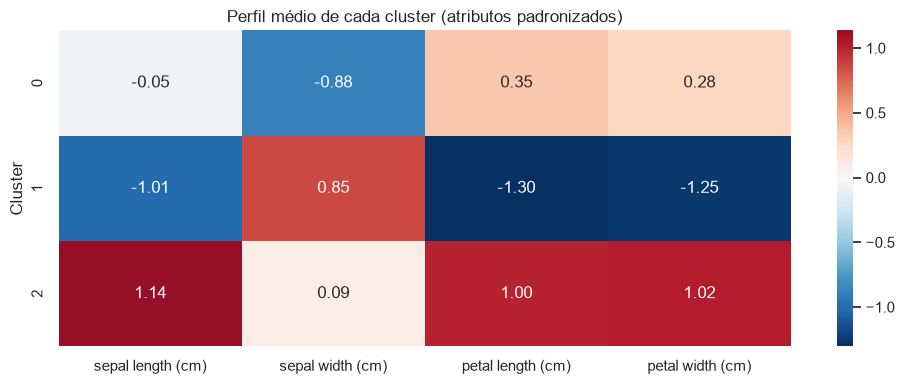

In [14]:
# Mapa de calor dos centroides: quais atributos caracterizam cada grupo?
plt.figure(figsize=(10, 4))
sns.heatmap(centroides_pad, annot=True, cmap="RdBu_r", center=0, fmt=".2f")
plt.title("Perfil médio de cada cluster (atributos padronizados)")
plt.ylabel("Cluster")
plt.tight_layout(); plt.show()

# 6. Visualizando os clusters

Como temos quatro variáveis, não podemos representar diretamente todas em um gráfico 2D. Primeiro vamos mostrar duas medidas originais; depois usaremos **PCA**, que projeta os dados em direções de maior variância.

**Cuidado:** uma projeção 2D pode esconder separações ou sobreposições existentes nas quatro dimensões. O K-Means abaixo foi treinado nas quatro variáveis padronizadas.

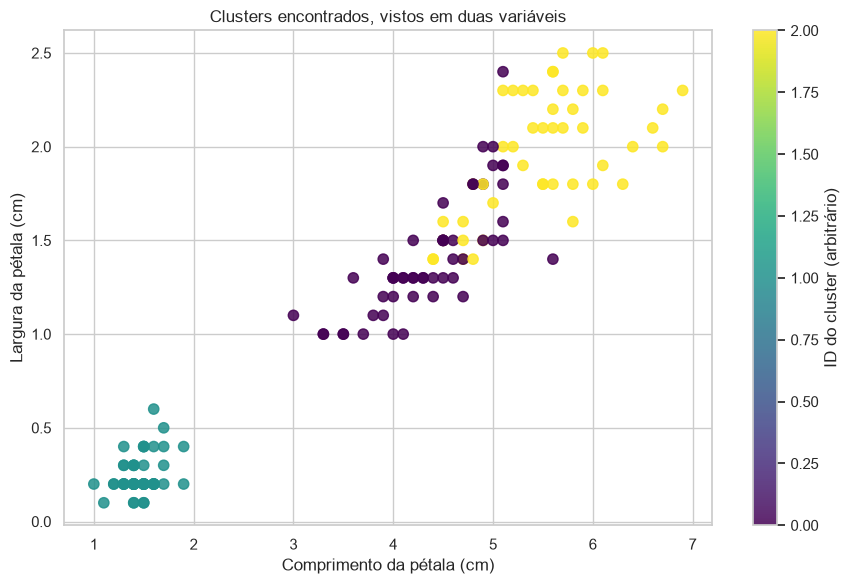

In [15]:
# Exibimos clusters usando duas medidas das pétalas.
plt.figure(figsize=(9, 6))
plt.scatter(X.iloc[:, 2], X.iloc[:, 3], c=clusters, cmap="viridis",
            s=55, alpha=0.85)
plt.xlabel("Comprimento da pétala (cm)")
plt.ylabel("Largura da pétala (cm)")
plt.title("Clusters encontrados, vistos em duas variáveis")
plt.colorbar(label="ID do cluster (arbitrário)")
plt.tight_layout(); plt.show()

## 6.1 O que é PCA?

**Análise de Componentes Principais (PCA)** é uma transformação linear que cria novos eixos ortogonais. A primeira componente captura a maior variância possível, a segunda captura a maior variância restante, e assim sucessivamente.

PCA **não é um algoritmo de clustering**. Aqui será usado principalmente para visualização. Vamos ajustar PCA nos mesmos atributos padronizados e projetar os pontos em duas componentes.

In [16]:
# Ajustamos PCA em quatro variáveis e conservamos duas componentes.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_pad)
print("Variância explicada pela CP1 e CP2:",
      np.round(pca.explained_variance_ratio_, 3))
print(f"Variância total representada no plano: {pca.explained_variance_ratio_.sum():.1%}")

Variância explicada pela CP1 e CP2: [0.73  0.229]
Variância total representada no plano: 95.8%


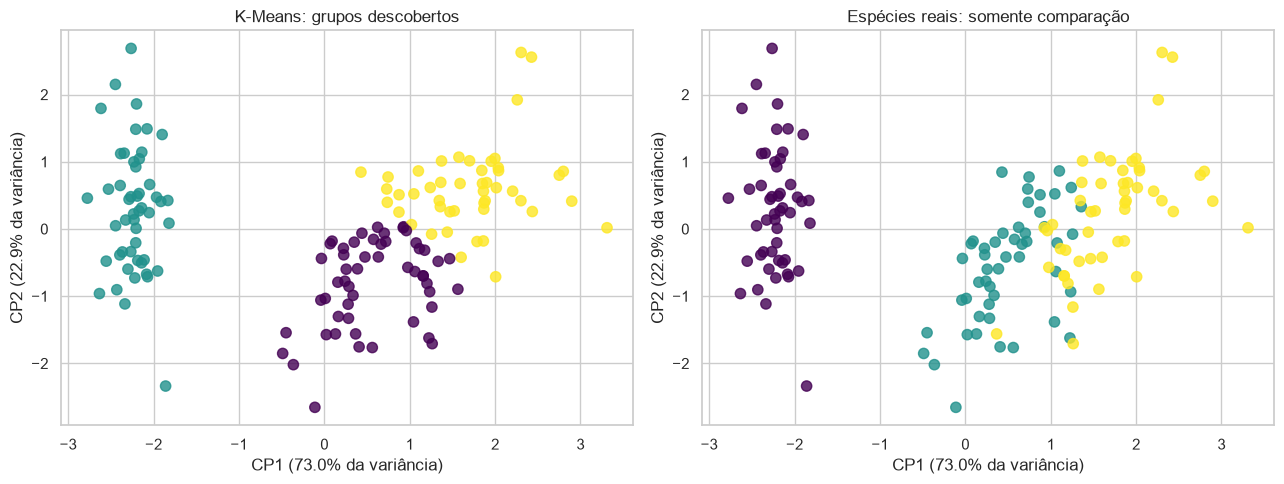

In [17]:
# Comparação: agrupamentos descobertos versus espécies de referência.
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
axs[0].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters,
               cmap="viridis", s=55, alpha=0.8)
axs[0].set_title("K-Means: grupos descobertos")
axs[1].scatter(X_pca[:, 0], X_pca[:, 1], c=especies,
               cmap="viridis", s=55, alpha=0.8)
axs[1].set_title("Espécies reais: somente comparação")
for ax in axs:
    ax.set_xlabel(f"CP1 ({pca.explained_variance_ratio_[0]:.1%} da variância)")
    ax.set_ylabel(f"CP2 ({pca.explained_variance_ratio_[1]:.1%} da variância)")
plt.tight_layout(); plt.show()

### O que observar?

Compare os painéis. Existe um conjunto que parece particularmente separado? Quais observações se sobrepõem? Os grupos encontrados não precisam coincidir perfeitamente com as espécies reais. **Nunca interprete uma cor como uma espécie sem verificar a correspondência.**

# 7. Como escolher o número de clusters K?

Não existe uma regra universal. Vamos usar duas ferramentas complementares:

**Método do cotovelo:** traça a inércia para diferentes K. A inércia sempre tende a diminuir quando aumentamos K; procuramos uma mudança de inclinação que sugira ganhos decrescentes. O cotovelo pode ser pouco nítido.

**Silhouette score:** para cada ponto compara a distância média aos pontos do próprio grupo ($a$) com a distância média ao grupo vizinho mais próximo ($b$):

$$s=\frac{b-a}{\max(a,b)}$$

Valores próximos de +1 sugerem melhor separação; perto de 0 indicam fronteiras ou sobreposição; negativos sugerem que o ponto está mais próximo de outro grupo. O escore global é a média dos pontos. **Silhouette não garante relevância biológica.**

In [18]:
# Testamos valores de K de 2 a 10.
valores_k = range(2, 11)
inercias = []
silhouettes = []

for k in valores_k:
    # Mantemos o mesmo protocolo para permitir comparação justa.
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMENTE)
    rotulos = km.fit_predict(X_pad)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pad, rotulos))

resultados_k = pd.DataFrame({"K": list(valores_k),
                             "Inércia": inercias,
                             "Silhouette": silhouettes})
display(resultados_k.round(3))

,K,Inércia,Silhouette
0,2,222.362,0.582
1,3,139.820,0.460
2,4,114.092,0.384
3,5,90.808,0.346
4,6,80.022,0.322
5,7,71.033,0.328
6,8,62.515,0.342
7,9,54.226,0.346
8,10,47.391,0.352


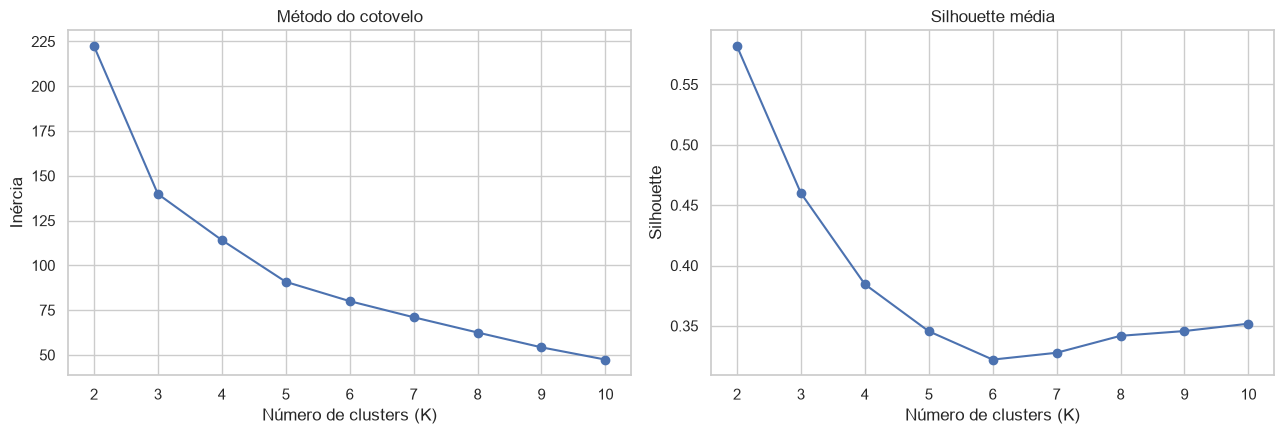

K com maior silhouette entre os testados: 2


In [19]:
# Mostramos o cotovelo e a silhouette lado a lado.
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(resultados_k["K"], resultados_k["Inércia"], "o-")
axs[0].set(title="Método do cotovelo", xlabel="Número de clusters (K)", ylabel="Inércia")
axs[1].plot(resultados_k["K"], resultados_k["Silhouette"], "o-")
axs[1].set(title="Silhouette média", xlabel="Número de clusters (K)", ylabel="Silhouette")
plt.tight_layout(); plt.show()
print("K com maior silhouette entre os testados:",
      int(resultados_k.loc[resultados_k["Silhouette"].idxmax(), "K"]))

### Discussão

O K que maximiza silhouette **pode ser diferente de 3**, mesmo que existam três espécies no dataset. Isso não é necessariamente um erro: os objetivos são diferentes. O algoritmo busca compactação e separação geométrica, não a taxonomia.

**Pergunta:** seria correto escolher K = 3 apenas porque já sabemos que o Iris tem três espécies? Para uma aula demonstrativa, sim, desde que isso seja declarado. Para uma investigação genuinamente não supervisionada, seria necessário justificar a decisão por critérios independentes e conhecimento do domínio.

# 8. Avaliação: o que significa um clustering bom?

### Métricas internas (não exigem classes reais)
- **Inércia:** soma das distâncias quadráticas aos centroides; depende de K e da escala.
- **Silhouette:** compactação e separação relativa dos grupos; costuma favorecer grupos bem separados.
- **Davies–Bouldin:** combina dispersão interna e proximidade entre clusters; em geral, menor é melhor.

### Métrica externa (exige rótulos de referência)
- **Adjusted Rand Index (ARI):** compara pares de observações que estão juntos/separados em duas partições e corrige o acordo esperado ao acaso. O valor 1 indica concordância perfeita; próximo de 0, acordo compatível com o acaso; pode ser negativo.

**Importante:** ARI não é usado para treinar o K-Means e não pressupõe que o ID do cluster seja igual ao código da espécie.

In [20]:
# Calculamos métricas internas e externas para o modelo com K = 3.
metricas = {
    "Inércia": modelo.inertia_,
    "Silhouette": silhouette_score(X_pad, clusters),
    "Davies–Bouldin": davies_bouldin_score(X_pad, clusters),
    "ARI (comparação externa)": adjusted_rand_score(especies, clusters)
}
for nome, valor in metricas.items():
    print(f"{nome}: {valor:.4f}")

Inércia: 139.8205
Silhouette: 0.4599
Davies–Bouldin: 0.8336
ARI (comparação externa): 0.6201


## 8.1 Matriz de contingência: clusters × espécies

Uma matriz de contingência mostra quantas flores de cada espécie foram atribuídas a cada cluster. **Ela não é uma matriz de confusão de um classificador supervisionado**, pois os IDs dos clusters não possuem correspondência pré-definida com os nomes das espécies.

Cluster,0,1,2
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36


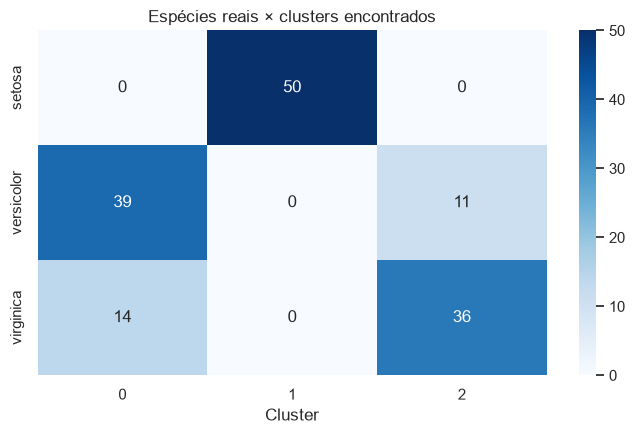

In [21]:
# Cruzamos os grupos descobertos com as espécies de referência.
tabela = pd.crosstab(pd.Series(especies.to_numpy(), name="Espécie"),
                     pd.Series(clusters, name="Cluster"))
tabela.index = [nomes_especies[i] for i in tabela.index]
display(tabela)
plt.figure(figsize=(7, 4.5))
sns.heatmap(tabela, annot=True, fmt="d", cmap="Blues")
plt.title("Espécies reais × clusters encontrados")
plt.tight_layout(); plt.show()

### Interpretação científica

A avaliação deve considerar **objetivo**, **qualidade dos dados**, **escolha dos atributos**, **estabilidade** e **significado dos grupos**. Um ARI alto não prova causalidade, nem valida uma hipótese biológica. Uma silhouette alta não garante que os grupos sejam espécies distintas.

# 9. Experimentos orientados

Agora vamos investigar como decisões metodológicas afetam os resultados. Esses experimentos ajudam a compreender que clustering não é uma operação neutra ou automática.

## 9.1 Com e sem padronização

Treinaremos dois modelos com K = 3, um nas medidas em centímetros e outro nas medidas padronizadas. Como as unidades são iguais, isso não significa que as escalas estatísticas sejam iguais: os atributos ainda têm amplitudes e dispersões diferentes.

In [22]:
# Comparamos duas representações do mesmo conjunto de flores.
km_bruto = KMeans(n_clusters=3, n_init=20, random_state=SEMENTE)
rot_bruto = km_bruto.fit_predict(X)
km_pad = KMeans(n_clusters=3, n_init=20, random_state=SEMENTE)
rot_pad = km_pad.fit_predict(X_pad)

comparacao = pd.DataFrame({
    "Representação": ["Sem padronização", "Com padronização"],
    "Silhouette": [silhouette_score(X, rot_bruto), silhouette_score(X_pad, rot_pad)],
    "ARI vs espécies": [adjusted_rand_score(especies, rot_bruto),
                        adjusted_rand_score(especies, rot_pad)]
})
display(comparacao.round(3))
print("Atenção: silhouettes calculadas em espaços diferentes não são diretamente equivalentes.")

,Representação,Silhouette,ARI vs espécies
0,Sem padronização,0.553,0.73
1,Com padronização,0.460,0.62


Atenção: silhouettes calculadas em espaços diferentes não são diretamente equivalentes.


## 9.2 E se usarmos apenas duas variáveis?

Escolher variáveis é uma decisão científica. Vamos comparar o K-Means com as quatro medidas e outro que usa apenas comprimento e largura da pétala, ambos padronizados em seus respectivos espaços.

ARI usando quatro variáveis: 0.62
ARI usando duas variáveis:   0.886
Silhouette (duas variáveis): 0.674


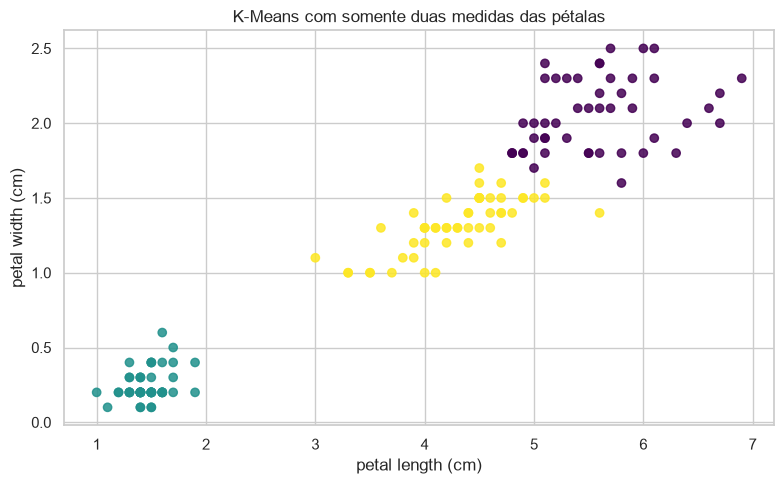

In [23]:
# Selecionamos somente as duas características das pétalas.
X_petalas = X.iloc[:, [2, 3]].copy()
X_petalas_pad = StandardScaler().fit_transform(X_petalas)
km_petalas = KMeans(n_clusters=3, n_init=20, random_state=SEMENTE)
rot_petalas = km_petalas.fit_predict(X_petalas_pad)

print("ARI usando quatro variáveis:", round(adjusted_rand_score(especies, clusters), 3))
print("ARI usando duas variáveis:  ", round(adjusted_rand_score(especies, rot_petalas), 3))
print("Silhouette (duas variáveis):", round(silhouette_score(X_petalas_pad, rot_petalas), 3))
plt.figure(figsize=(8, 5))
plt.scatter(X_petalas.iloc[:, 0], X_petalas.iloc[:, 1],
            c=rot_petalas, cmap="viridis", alpha=0.85)
plt.xlabel(X_petalas.columns[0]); plt.ylabel(X_petalas.columns[1])
plt.title("K-Means com somente duas medidas das pétalas")
plt.tight_layout(); plt.show()

## 9.3 A inicialização pode alterar o resultado?

Testaremos várias sementes com `n_init=1` para observar soluções individuais. Isso **não** é o protocolo recomendado para o modelo final: a intenção é demonstrar a sensibilidade à inicialização. Depois compare com o uso de `n_init=20`.

In [24]:
# Treinamos uma única inicialização por semente para visualizar a variabilidade.
linhas = []
for semente in range(10):
    tentativa = KMeans(n_clusters=3, init="random", n_init=1,
                       random_state=semente)
    rot = tentativa.fit_predict(X_pad)
    linhas.append({"Semente": semente, "Inércia": tentativa.inertia_,
                   "ARI": adjusted_rand_score(especies, rot)})
df_sementes = pd.DataFrame(linhas)
display(df_sementes.round(3))
print("Inércia com k-means++ e 20 inicializações:", round(modelo.inertia_, 3))

,Semente,Inércia,ARI
0,0,140.902,0.645
1,1,140.902,0.645
2,2,140.082,0.641
3,3,140.902,0.645
4,4,140.902,0.645
5,5,191.025,0.433
6,6,139.820,0.620
7,7,140.082,0.641
8,8,140.033,0.592
9,9,140.033,0.592


Inércia com k-means++ e 20 inicializações: 139.82


## 9.4 Síntese da aula

**O que aprendemos?** O K-Means é um algoritmo não supervisionado que minimiza a soma das distâncias quadráticas aos centroides. A seleção de atributos e a padronização modificam o espaço geométrico e, portanto, podem alterar os grupos. K deve ser justificado; a inércia, a silhouette e as métricas externas respondem a perguntas diferentes. PCA é uma projeção visual, não uma garantia de separação.

**Antes de interpretar um cluster como entidade biológica**, pergunte: há coerência com o domínio? O agrupamento é estável? Os dados representam adequadamente o fenômeno? Há fatores de confusão?

# 📝 Exercício final — Versão Simplificada

**Modalidade:** Individual ou em duplas  
**Entrega:** Uma cópia do notebook com as respostas e códigos executados.

### Parte A — Conceitos Práticos (5 pontos)
1. (2,5 pontos) Por que não passamos a coluna das espécies (`target`) para o algoritmo K-Means durante o treinamento?
2. (2,5 pontos) O que acontece com a distância entre os pontos se não padronizarmos os dados antes de rodar o K-Means?

### Parte B — Prática Direta (5 pontos)

3. (2,5 pontos) Complete o código abaixo para treinar o K-Means com **K = 3** utilizando os dados padronizados (`X_pad`).
4. (2,5 pontos) Calcule e exiba o coeficiente de Silhouette para esse modelo.

In [25]:
# EXERCÍCIO 3 — Treine o K-Means com K = 3 nos dados padronizados
# Dica: use KMeans(n_clusters=3, random_state=42)

# 1. Instancie o modelo
modelo_simples = KMeans(n_clusters=3, n_init=20, random_state=42)

# 2. Treine o modelo e obtenha os rótulos de cluster usando X_pad
rotulos_simples = modelo_simples.fit_predict(X_pad)

print("Grupos atribuídos para as primeiras 10 flores:")
print(rotulos_simples[:10])

Grupos atribuídos para as primeiras 10 flores:
[1 1 1 1 1 1 1 1 1 1]


In [26]:
# EXERCÍCIO 4 — Calcule a Silhouette do modelo treinado
# Dica: use a função silhouette_score(X_pad, rotulos_simples)

escore_sil = silhouette_score(X_pad, rotulos_simples)

print(f"O escore de Silhouette para K=3 é: {escore_sil:.4f}")

O escore de Silhouette para K=3 é: 0.4599


Respostas Parte A:

1. Porque o K-Means é não supervisionado, ele tem que achar os grupos só pelas medidas. Se passar a espécie, ele usaria a resposta pra agrupar e não teria sentido avaliar depois (o ARI ficaria viciado). A espécie fica guardada só pra comparar no final.

2. A distância fica dominada pelos atributos com maior variação. No Iris, o comprimento da pétala varia bem mais que a largura da sépala, então ele pesaria mais na hora de formar os grupos. Padronizando, todos os atributos ficam com média 0 e desvio 1 e contribuem de forma parecida.


## Checklist de entrega

- [x] Respondi às quatro perguntas teóricas com minhas palavras.
- [x] Executei a comparação de K = 2 a K = 6.
- [x] Apresentei gráficos com títulos e eixos identificados.
- [x] Justifiquei K sem consultar as espécies reais.
- [x] Calculei e interpretei ARI apenas após escolher K.
- [x] Comparei os resultados com e sem padronização.
- [x] Escrevi uma conclusão crítica com limitações.

### Referências para aprofundamento
- [Scikit-learn — KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Scikit-learn — Clustering](https://scikit-learn.org/stable/modules/clustering.html)
- [Scikit-learn — StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [Scikit-learn — PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [Scikit-learn — Silhouette score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)

**Fim da aula.**